Part 2: Classification and model improvement

Name: Pfunzo Madzhiga

Student no.: ST10543942

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the breast cancer dataset
data = load_breast_cancer()

# Create a DataFrame containing the 30 features
df = pd.DataFrame(data.data, columns=data.feature_names)

# Define malignant as 1 and benign as 0
y = (data.target == 0).astype(int)

# Add the diagnosis column using NumPy's where() function
df["diagnosis"] = np.where(y == 1, "Malignant", "Benign")

# Display the results
print("Dataset loaded successfully.")
print("Number of records:", df.shape[0])
print("Number of features:", len(data.feature_names))

df.head()

Dataset loaded successfully.
Number of records: 569
Number of features: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [4]:
print(df.isnull().sum().sum())

0


In [5]:
print("\nDuplicate records:", df.duplicated().sum())


Duplicate records: 0


In [6]:
display(df.describe())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


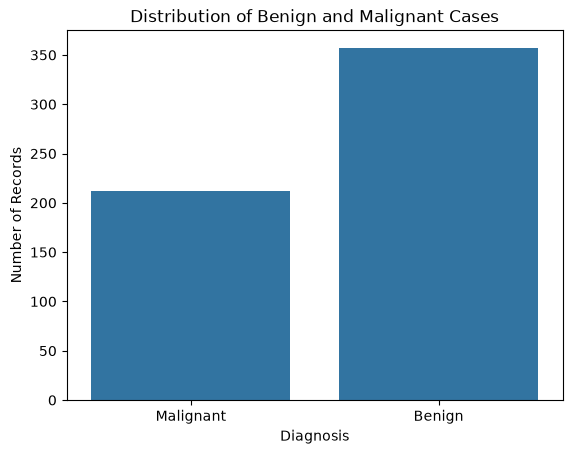

In [21]:
sns.countplot(data=df, x="diagnosis")
plt.title("Distribution of Benign and Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.show()

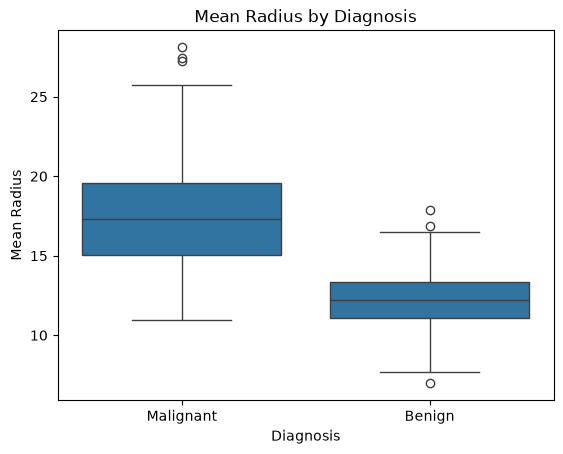

In [8]:
plot_df = df.copy()

sns.boxplot(data=plot_df, x="diagnosis", y="mean radius")
plt.title("Mean Radius by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.show()

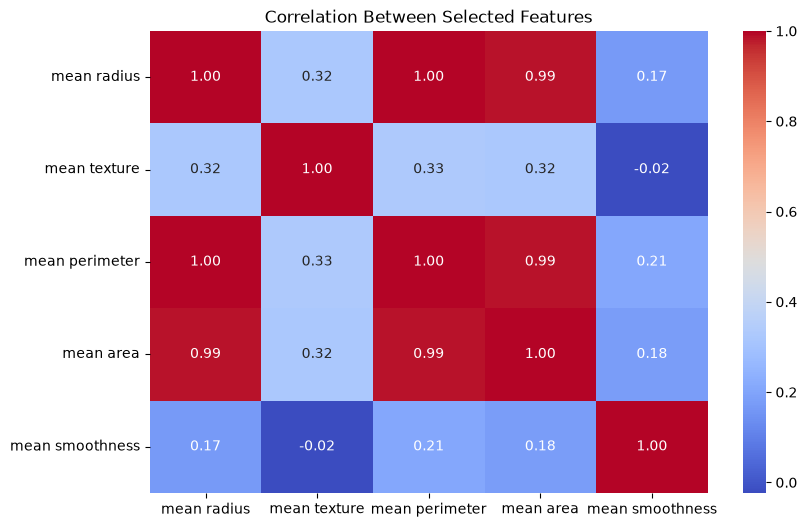

In [9]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df[["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Selected Features")
plt.show()

In [10]:
x = df.drop(columns=["diagnosis"])

In [11]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", x_train.shape[0])
print("Testing records:", x_test.shape[0])

Training records: 455
Testing records: 114


In [12]:
model = Pipeline([
    ("feature_selection", SelectKBest(score_func=f_classif, k=15)),
    ("scaler", StandardScaler()),
    ("classifier",LogisticRegression(C=1.0, max_iter=5000))
])

In [13]:
model.fit(x_train, y_train)

print("Logistic Regression model trained successfully")

Logistic Regression model trained successfully


In [14]:
selector = model.named_steps["feature_selection"]

selected_features = x_train.columns[selector.get_support()]

print("selected features")
for feature in selected_features:
    print(feature)

selected features
mean radius
mean perimeter
mean area
mean compactness
mean concavity
mean concave points
radius error
perimeter error
area error
worst radius
worst perimeter
worst area
worst compactness
worst concavity
worst concave points


In [15]:
y_pred = model.predict(x_test)

In [16]:
y_prob = model.predict_proba(x_test)[:, 1]

In [17]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

Accuracy: 0.9737
Precision: 1.0
Recall: 0.9286
F1-score: 0.963
ROC-AUC: 0.9993

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



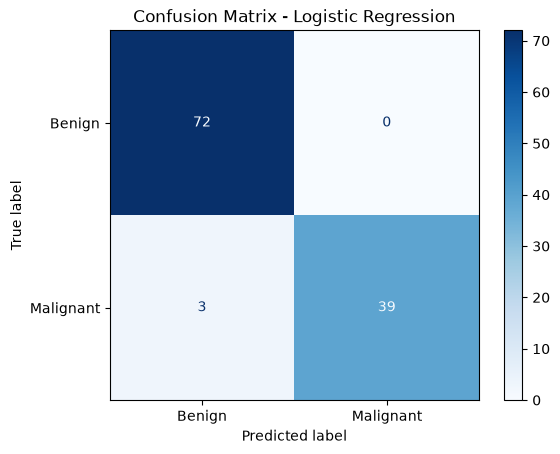

In [18]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

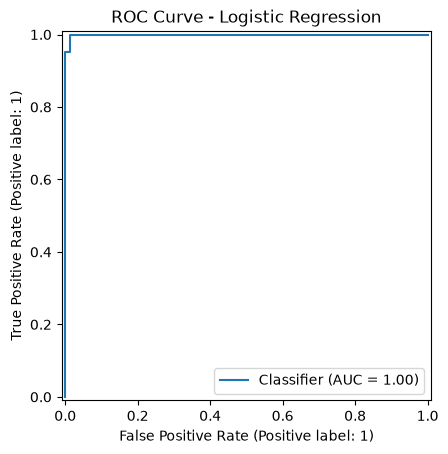

In [19]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("ROC Curve - Logistic Regression")
plt.show()

In [20]:
results = []

for c_value in [0.01, 0.1, 1.0, 10.0]:
    test_model = Pipeline([
        ("feature_selection", SelectKBest(f_classif, k=15)),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=c_value,
            max_iter=5000
        ))
    ])

    test_model.fit(x_train, y_train)

    predictions = test_model.predict(x_test)
    probabilities = test_model.predict_proba(x_test)[:, 1]

    results.append({
        "C": c_value,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,C,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.01,0.9211,0.9714,0.8095,0.8831,0.9960
1,0.10,0.9474,0.9737,0.8810,0.9250,0.9977
2,1.00,0.9737,1.0000,0.9286,0.9630,0.9993
3,10.00,0.9825,1.0000,0.9524,0.9756,0.9993
